# Unemployment Analysis in India

**CodeAlpha Data Science Internship — Task 2: Unemployment Analysis with Python**

## Objective
Clean, explore and visualize unemployment-rate data across Indian states, measure the
impact of Covid-19, identify key patterns, and draw insights that could inform
economic and social policy.

## Datasets
1. **Unemployment in India.csv**: monthly data, May 2019 to Jun 2020, 28 states, split into
Rural and Urban.
2. **Unemployment_Rate_upto_11_2020.csv**: monthly state-level data, Jan to Oct 2020, with a
regional grouping (North, South, West, East, Northeast).

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 1. Load the Datasets

We load both files into separate DataFrames. They overlap in Jan to Jun 2020 but are
structured differently, so we analyze them separately rather than merging them.

In [3]:
# Use your actual file names if they differ
df_india = pd.read_csv('Unemployment in India.csv')
df_2020 = pd.read_csv('Unemployment_Rate_upto_11_2020.csv')

print("India (May 2019 - Jun 2020):", df_india.shape)
print("2020 (Jan - Oct 2020):", df_2020.shape)

India (May 2019 - Jun 2020): (768, 7)
2020 (Jan - Oct 2020): (267, 9)


In [4]:
df_india.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [5]:
df_2020.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


## 2. Initial Data Inspection

Before cleaning, we check data types, missing values, duplicates and column names in both
datasets.

In [12]:
# Data types and non-null counts
df_india.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [13]:
# Missing values per column
df_india.isnull().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [14]:
# Number of exact duplicate rows
df_india.duplicated().sum()

np.int64(27)

In [15]:
# Column names exactly as stored (look closely for stray spaces)
df_india.columns.tolist()

['Region',
 ' Date',
 ' Frequency',
 ' Estimated Unemployment Rate (%)',
 ' Estimated Employed',
 ' Estimated Labour Participation Rate (%)',
 'Area']

In [16]:
# Summary statistics for the numeric columns
df_india.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [17]:
df_2020.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    object 
 1    Date                                     267 non-null    object 
 2    Frequency                                267 non-null    object 
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                  267 non-null    object 
 7   longitude                                 267 non-null    float64
 8   latitude                                  267 non-null    float64
dtypes: float64(4), int64(1), object(4)
memory usage: 18.9+ KB


In [18]:
df_2020.isnull().sum()

Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64

In [19]:

df_2020.duplicated().sum()

np.int64(0)

In [20]:
df_2020.columns.tolist()

['Region',
 ' Date',
 ' Frequency',
 ' Estimated Unemployment Rate (%)',
 ' Estimated Employed',
 ' Estimated Labour Participation Rate (%)',
 'Region.1',
 'longitude',
 'latitude']

In [21]:
df_2020.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),longitude,latitude
count,267.000000,2.670000e+02,267.000000,267.000000,267.000000
mean,12.236929,1.396211e+07,41.681573,22.826048,80.532425
std,10.803283,1.336632e+07,7.845419,6.270731,5.831738
min,0.500000,1.175420e+05,16.770000,10.850500,71.192400
25%,4.845000,2.838930e+06,37.265000,18.112400,76.085600
50%,9.650000,9.732417e+06,40.390000,23.610200,79.019300
75%,16.755000,2.187869e+07,44.055000,27.278400,85.279900
max,75.850000,5.943376e+07,69.690000,33.778200,92.937600


## 3. Data Cleaning

**India dataset**
- Remove the 28 completely blank rows (this also removes the 27 "duplicates", since blank
rows are identical to each other).
- Strip stray spaces from the column names and shorten the long ones.
- Convert `Date` from text to a real datetime.
- Drop `Frequency`: every row is monthly, so it carries no information.

**2020 dataset**
- Same column and date cleanup.
- Rename the second `Region` column (North, South, West, East, Northeast) to `Zone`.
- Fix the swapped `latitude` / `longitude` labels.

In [22]:
# Remove the 28 completely blank rows (this also removes the 27 "duplicates",
# because the blank rows are identical to each other)
df_india = df_india.dropna(how='all')

# Strip stray spaces from column names (e.g. ' Date' -> 'Date')
df_india.columns = df_india.columns.str.strip()

# Shorten the long column names
df_india = df_india.rename(columns={
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation_Rate'
})

# Convert Date from text to a real datetime (the values look like ' 31-05-2019')
df_india['Date'] = pd.to_datetime(df_india['Date'].str.strip(), format='%d-%m-%Y')

In [23]:
# Frequency has mixed ' Monthly' / 'Monthly' values; strip, confirm there is only one
# value left, then drop it since every row is monthly
df_india['Frequency'] = df_india['Frequency'].str.strip()
print(df_india['Frequency'].unique())
df_india = df_india.drop(columns=['Frequency'])

['Monthly']


In [29]:
# Verify the cleaning worked
print(df_india.shape)                  
print(df_india.isnull().sum().sum())   
print(df_india.duplicated().sum())     
df_india.info()

(740, 6)
0
0
<class 'pandas.core.frame.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Region                     740 non-null    object        
 1   Date                       740 non-null    datetime64[ns]
 2   Unemployment_Rate          740 non-null    float64       
 3   Employed                   740 non-null    float64       
 4   Labour_Participation_Rate  740 non-null    float64       
 5   Area                       740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(2)
memory usage: 40.5+ KB


In [26]:
# Strip stray spaces from column names
df_2020.columns = df_2020.columns.str.strip()

df_2020 = df_2020.rename(columns={
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation_Rate',
    'Region.1': 'Zone',          # pandas renamed the duplicate 'Region' column to 'Region.1'
    'longitude': 'latitude',     # the file's latitude/longitude labels are swapped
    'latitude': 'longitude'      # (e.g. Assam shows "longitude" 26.2), so swap them back
})

# Convert Date from text to a real datetime
df_2020['Date'] = pd.to_datetime(df_2020['Date'].str.strip(), format='%d-%m-%Y')

# Frequency is ' M' (monthly) on every row, so it carries no information
df_2020 = df_2020.drop(columns=['Frequency'])

In [28]:
# Verify the cleaning worked
print(df_2020.shape)                   
print(df_2020.columns.tolist())
df_2020.head()

(267, 8)
['Region', 'Date', 'Unemployment_Rate', 'Employed', 'Labour_Participation_Rate', 'Zone', 'latitude', 'longitude']


,Region,Date,Unemployment_Rate,Employed,Labour_Participation_Rate,Zone,latitude,longitude
0,Andhra Pradesh,2020-01-31,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,2020-02-29,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,2020-03-31,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,2020-04-30,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,2020-05-31,17.43,12988845,36.46,South,15.9129,79.74


## 4. Exploratory Data Analysis

We explore how unemployment rates are distributed and how they changed month by month.
Note that every "average" below is a simple average across states (or state-area
combinations), not an official population-weighted national figure.

### 4.1 Distribution of Unemployment Rates

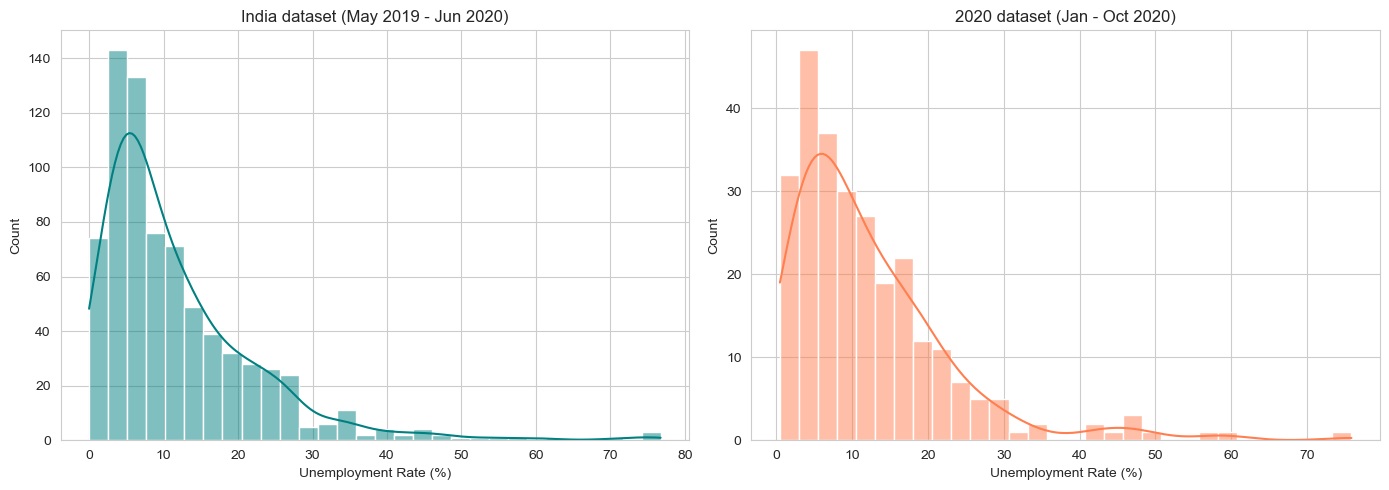

In [30]:
# Distribution of unemployment rates in both datasets
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_india['Unemployment_Rate'], bins=30, kde=True, color='teal', ax=axes[0])
axes[0].set_title("India dataset (May 2019 - Jun 2020)")
axes[0].set_xlabel("Unemployment Rate (%)")

sns.histplot(df_2020['Unemployment_Rate'], bins=30, kde=True, color='coral', ax=axes[1])
axes[1].set_title("2020 dataset (Jan - Oct 2020)")
axes[1].set_xlabel("Unemployment Rate (%)")

plt.tight_layout()
plt.show()

In [31]:
# Compare mean vs median, and count observations above 20%
for name, d in [("India", df_india), ("2020", df_2020)]:
    u = d['Unemployment_Rate']
    print(f"{name}: mean {u.mean():.2f} | median {u.median():.2f} | skew {u.skew():.2f} | above 20%: {(u > 20).sum()} of {len(u)}")

India: mean 11.79 | median 8.35 | skew 2.22 | above 20%: 129 of 740
2020: mean 12.24 | median 9.65 | skew 2.22 | above 20%: 45 of 267


**Observation:** In both datasets the distribution is strongly right-skewed (skewness about
2.2): most state-level readings sit below 10%, but a long tail stretches past 20% and up to
76.7%. The mean (11.8% in the India dataset) sits well above the median (8.4%) because of that
tail. About 17% of readings exceed 20%. Not all of these are lockdown readings: only about 40%
fall in April and May 2020, and the rest are spread across all months, showing that some states
had chronically high unemployment even before Covid-19.

In [32]:
# Rows reporting exactly 0% unemployment are suspicious, so check where they come from
df_india[df_india['Unemployment_Rate'] == 0][['Region', 'Date', 'Area', 'Employed']]

,Region,Date,Area,Employed
25,Assam,2020-06-30,Rural,7544937.0
51,Chhattisgarh,2020-04-30,Rural,6534321.0
77,Goa,2020-02-29,Rural,171672.0
231,Puducherry,2019-05-31,Rural,172474.0
232,Puducherry,2019-06-30,Rural,184527.0
233,Puducherry,2019-07-31,Rural,139227.0
235,Puducherry,2019-09-30,Rural,175718.0
237,Puducherry,2019-11-30,Rural,142787.0
274,Sikkim,2020-04-30,Rural,133399.0
617,Puducherry,2019-06-30,Urban,304369.0


**Data quality note:** 11 rows report exactly 0% unemployment, 7 of them from Puducherry and 9
from rural areas. A true 0% is unlikely and may reflect small survey samples. There is no clear
evidence of an error, so we keep these rows but treat them with caution.

### 4.2 National Monthly Trend

Tracking the average state unemployment rate month by month in both datasets.

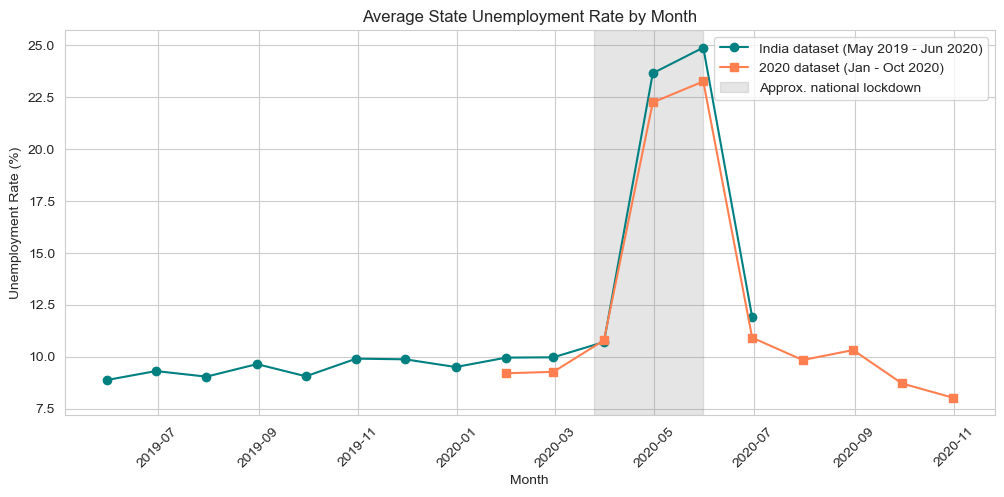

In [33]:
# Average state-level unemployment rate per month, for each dataset
# (a simple average across states, not an official national figure)
monthly_india = df_india.groupby('Date')['Unemployment_Rate'].mean()
monthly_2020 = df_2020.groupby('Date')['Unemployment_Rate'].mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_india.index, monthly_india.values, marker='o', color='teal',
         label='India dataset (May 2019 - Jun 2020)')
plt.plot(monthly_2020.index, monthly_2020.values, marker='s', color='coral',
         label='2020 dataset (Jan - Oct 2020)')

# Shade the approximate national lockdown period (25 Mar - 31 May 2020)
plt.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-05-31'),
            color='grey', alpha=0.2, label='Approx. national lockdown')

plt.title("Average State Unemployment Rate by Month")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.show()

In [34]:
# The same numbers as a table
pd.concat([monthly_india.rename('India dataset'), monthly_2020.rename('2020 dataset')], axis=1).round(2)

,India dataset,2020 dataset
Date,,
2019-05-31,8.87,NaN
2019-06-30,9.30,NaN
2019-07-31,9.03,NaN
2019-08-31,9.64,NaN
2019-09-30,9.05,NaN
2019-10-31,9.90,NaN
2019-11-30,9.87,NaN
2019-12-31,9.50,NaN
2020-01-31,9.95,9.20


**Observation:** From May to December 2019 the average state unemployment rate stayed in a
narrow band of roughly 9 to 10%. It edged up to about 10.7% in March 2020, then jumped to
roughly 22 to 24% in April and 23 to 25% in May, when the national lockdown began on 25 March.
By June it had fallen back to about 11 to 12%, and by October the 2020 dataset shows about 8%,
below its January level (9.2%). The two datasets tell the same story, but their levels differ
slightly because the India dataset averages rural and urban rows and also includes Chandigarh.

## 5. Impact of Covid-19

We use the 2020 dataset, which covers January to October 2020, to compare three phases:
before the lockdown (Jan to Mar), the lockdown months (Apr to May), and the recovery
(Jun to Oct). India's national lockdown began on 25 March 2020.

### 5.1 Unemployment Before, During and After the Lockdown

In [35]:
# Label each month with its phase of the pandemic
def assign_phase(date):
    if date <= pd.Timestamp('2020-03-31'):
        return 'Pre-lockdown (Jan-Mar)'
    elif date <= pd.Timestamp('2020-05-31'):
        return 'Lockdown (Apr-May)'
    else:
        return 'Recovery (Jun-Oct)'

df_2020['Phase'] = df_2020['Date'].apply(assign_phase)

# Keep the phases in chronological order (alphabetical order would mix them up)
phase_order = ['Pre-lockdown (Jan-Mar)', 'Lockdown (Apr-May)', 'Recovery (Jun-Oct)']

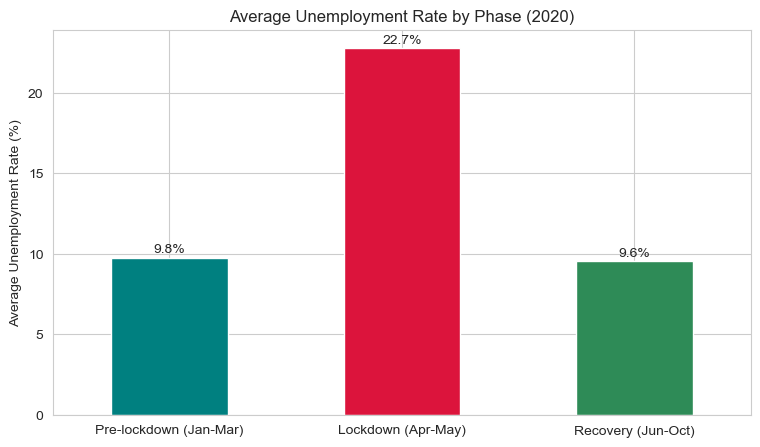

In [36]:
# Average unemployment rate in each phase
phase_avg = df_2020.groupby('Phase')['Unemployment_Rate'].mean().reindex(phase_order)

plt.figure(figsize=(9, 5))
phase_avg.plot(kind='bar', color=['teal', 'crimson', 'seagreen'])
plt.ylabel("Average Unemployment Rate (%)")
plt.xlabel("")
plt.title("Average Unemployment Rate by Phase (2020)")
plt.xticks(rotation=0)

# Print the value above each bar
for i, v in enumerate(phase_avg):
    plt.text(i, v + 0.3, f"{v:.1f}%", ha='center')
plt.show()

**Observation:** The average state unemployment rate rose from 9.8% before the lockdown to
22.8% during April and May, more than doubling, and then fell back to 9.6% over June to
October. On average, the labour market returned to its pre-lockdown level once restrictions
eased. The next section shows that this average hides large differences between states.

### 5.2 Hardest-Hit States

We compare each state's average rate during the lockdown with its pre-lockdown average to see
where the shock was largest.

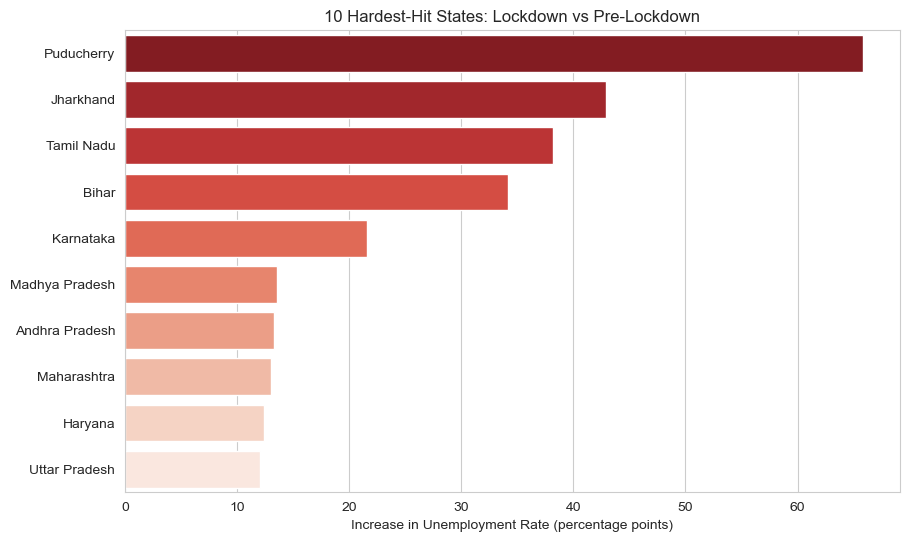

In [37]:
# Average unemployment rate per state in each phase
state_phase = df_2020.pivot_table(index='Region', columns='Phase', values='Unemployment_Rate')
state_phase = state_phase[phase_order]   # put the columns in chronological order
state_phase.columns = ['Pre_lockdown', 'Lockdown', 'Recovery']

# Increase in percentage points from before the lockdown to during it
state_phase['Increase'] = state_phase['Lockdown'] - state_phase['Pre_lockdown']

top10 = state_phase.sort_values('Increase', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top10['Increase'], y=top10.index, hue=top10.index, legend=False, palette='Reds_r')
plt.xlabel("Increase in Unemployment Rate (percentage points)")
plt.ylabel("")
plt.title("10 Hardest-Hit States: Lockdown vs Pre-Lockdown")
plt.show()

In [38]:
# The numbers behind the chart
top10.round(1)

,Pre_lockdown,Lockdown,Recovery,Increase
Region,,,,
Puducherry,1.2,67.0,8.4,65.8
Jharkhand,10.2,53.2,11.7,42.9
Tamil Nadu,3.4,41.5,5.8,38.1
Bihar,12.1,46.3,13.2,34.2
Karnataka,3.3,24.9,3.4,21.6
Madhya Pradesh,3.6,17.2,4.7,13.5
Andhra Pradesh,5.7,19.0,6.3,13.3
Maharashtra,5.1,18.2,5.6,13.0
Haryana,23.7,36.1,26.3,12.4


In [39]:
# How uneven was the shock and the recovery?
print("Median increase across all states:", round(state_phase['Increase'].median(), 1), "points")
print("States that did NOT rise during the lockdown:", (state_phase['Increase'] < 0).sum())
print("States still above their pre-lockdown rate in the recovery phase:",
      (state_phase['Recovery'] > state_phase['Pre_lockdown']).sum(), "of", len(state_phase))

Median increase across all states: 11.1 points
States that did NOT rise during the lockdown: 5
States still above their pre-lockdown rate in the recovery phase: 16 of 27


**Observation:** The shock was very uneven. Puducherry was hit hardest by far: its average
rate jumped from about 1% to 67% (peaking at 75.8% in April), followed by Jharkhand (+43
points), Tamil Nadu (+38) and Bihar (+34). The median state rose by about 11 points, but 5 of
the 27 states (Chhattisgarh, Himachal Pradesh, Jammu & Kashmir, Sikkim and Uttarakhand) saw no
rise at all. Recovery was uneven too: although the overall average returned to normal, 16 of
27 states were still above their pre-lockdown rate in June to October, including Bihar,
Jharkhand, Haryana and Puducherry.

### 5.3 Regional Comparison

The 2020 dataset groups states into five zones (North, South, East, West, Northeast). We
compare how each zone was hit and how it recovered. Zone figures are simple averages of
4 to 8 states, so a single state can pull a zone's average a long way.

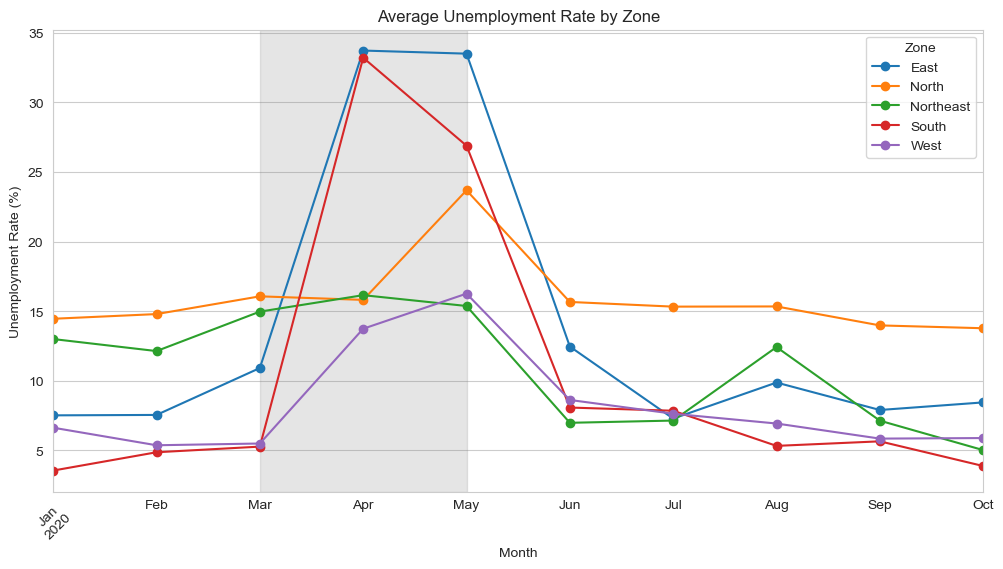

In [40]:
# Average unemployment rate per month in each zone
zone_monthly = df_2020.pivot_table(index='Date', columns='Zone', values='Unemployment_Rate')

zone_monthly.plot(figsize=(12, 6), marker='o')

# Shade the approximate national lockdown period
plt.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-05-31'), color='grey', alpha=0.2)

plt.title("Average Unemployment Rate by Zone")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title='Zone')
plt.show()

In [41]:
# Average rate per zone in each phase, as a table
zone_phase = df_2020.pivot_table(index='Zone', columns='Phase', values='Unemployment_Rate')[phase_order]
zone_phase.round(1)

Phase,Pre-lockdown (Jan-Mar),Lockdown (Apr-May),Recovery (Jun-Oct)
Zone,,,
East,8.7,33.6,9.2
North,15.1,20.0,14.8
Northeast,13.5,15.8,7.7
South,4.6,30.0,6.2
West,5.8,15.0,7.0


**Observation:** The East and South were hit hardest, averaging about 34% and 30% during the
lockdown (up from 8.7% and 4.6% before it), while the West (15.0%) and Northeast (15.8%) saw
much smaller rises. The East and South peaked in April, with the South easing in May (33.2% to
26.9%), but the North peaked later, in May (23.7%). Recovery was strong in the South, which
ended October at 3.9%, below its pre-lockdown level. The North tells a different story: it had
the highest rate in every month except April and May, and it was still the highest in October
(13.8%), so its unemployment looks chronic rather than Covid-driven. Note that the East's
figure is pulled up by Bihar and Jharkhand, and the South's by Puducherry and Tamil Nadu.

### 5.4 Jobs Lost and Recovered

The `Employed` column estimates how many people were employed in each state. Summing it across
states shows how total employment moved. These are the dataset's own estimates, so treat the
figures as indicative.

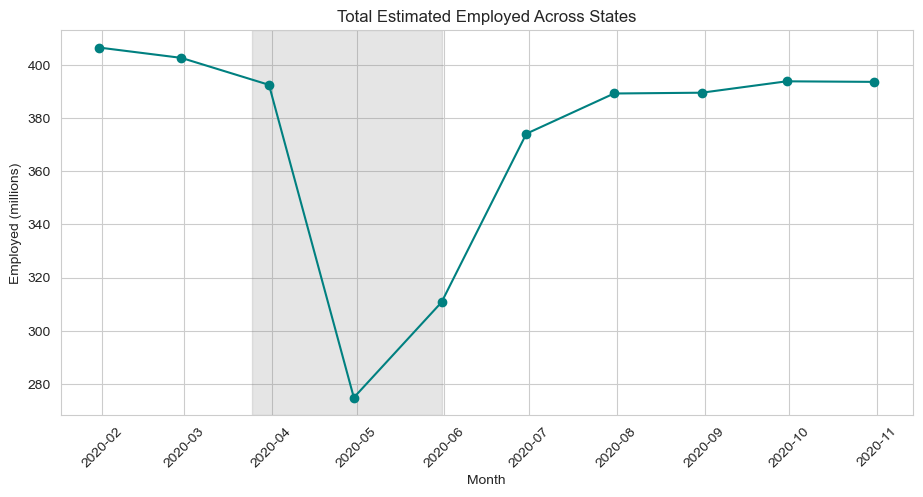

In [42]:
# Total estimated employed across all states, per month, in millions
employed_monthly = df_2020.groupby('Date')['Employed'].sum() / 1e6

plt.figure(figsize=(11, 5))
plt.plot(employed_monthly.index, employed_monthly.values, marker='o', color='teal')

# Shade the approximate national lockdown period
plt.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-05-31'), color='grey', alpha=0.2)

plt.title("Total Estimated Employed Across States")
plt.xlabel("Month")
plt.ylabel("Employed (millions)")
plt.xticks(rotation=45)
plt.show()

In [43]:
# The same numbers as a table, plus the March-to-April change
print(employed_monthly.round(1))
print(f"\nChange from March to April: {employed_monthly['2020-04-30'] - employed_monthly['2020-03-31']:.1f} million")

Date
2020-01-31    406.6
2020-02-29    402.7
2020-03-31    392.5
2020-04-30    274.8
2020-05-31    310.7
2020-06-30    374.1
2020-07-31    389.3
2020-08-31    389.6
2020-09-30    393.9
2020-10-31    393.7
Name: Employed, dtype: float64

Change from March to April: -117.7 million


**Observation:** Estimated employment fell by about 118 million (30%) in a single month, from
392.5 million in March to 274.8 million in April. It then recovered in stages: 310.7 million in
May and 374.1 million in June. By September and October it had climbed back to about 394
million, still roughly 2% below its February level of 402.7 million. The speed of the collapse,
and of the rebound once restrictions eased, shows that the shock came from the lockdown itself
rather than a lasting structural change.

## 6. Rural vs Urban

Only the India dataset (May 2019 to Jun 2020) splits unemployment into rural and urban areas,
so this section uses it. Chandigarh has urban data only, so it is left out of the state-by-state
rural vs urban comparisons.

### 6.1 Monthly Trend by Area

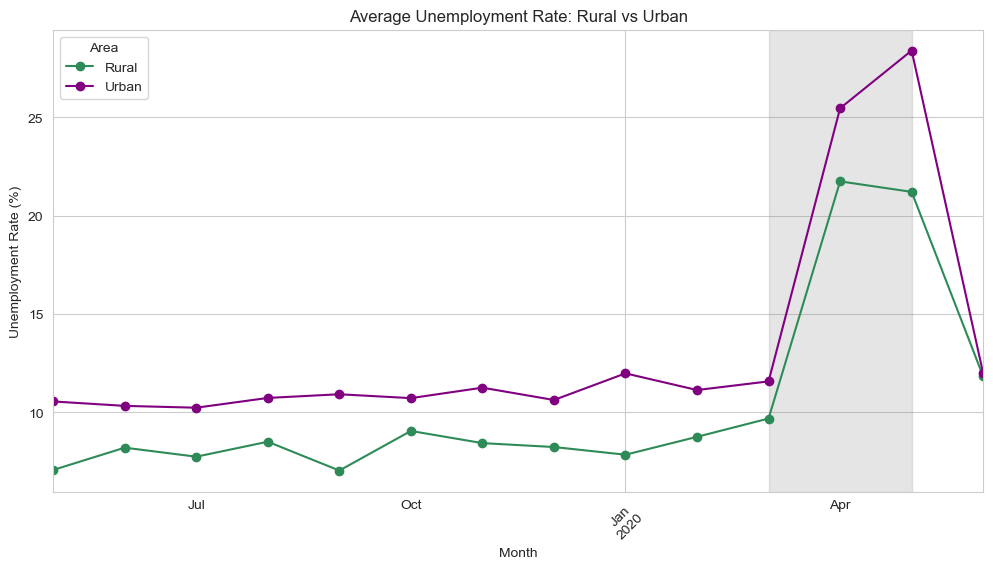

In [44]:
# Average unemployment rate per month for rural and urban areas
area_monthly = df_india.pivot_table(index='Date', columns='Area', values='Unemployment_Rate')

area_monthly.plot(figsize=(12, 6), marker='o', color=['seagreen', 'purple'])

# Shade the approximate national lockdown period
plt.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-05-31'), color='grey', alpha=0.2)

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title='Area')
plt.show()

In [45]:
# The same numbers as a table
area_monthly.round(1)

Area,Rural,Urban
Date,,
2019-05-31,7.1,10.6
2019-06-30,8.2,10.3
2019-07-31,7.7,10.2
2019-08-31,8.5,10.7
2019-09-30,7.0,10.9
2019-10-31,9.1,10.7
2019-11-30,8.4,11.3
2019-12-31,8.2,10.6
2020-01-31,7.8,12.0


**Observation:** Urban unemployment was higher than rural in every month. Before the lockdown
urban sat around 10 to 12% against 7 to 10% for rural. Both jumped sharply in April 2020, rural
to 21.7% and urban to 25.5%, and in May the gap widened further (urban 28.4% vs rural 21.2%).
By June 2020 the two had converged at about 12%.

### 6.2 Rural vs Urban by Phase

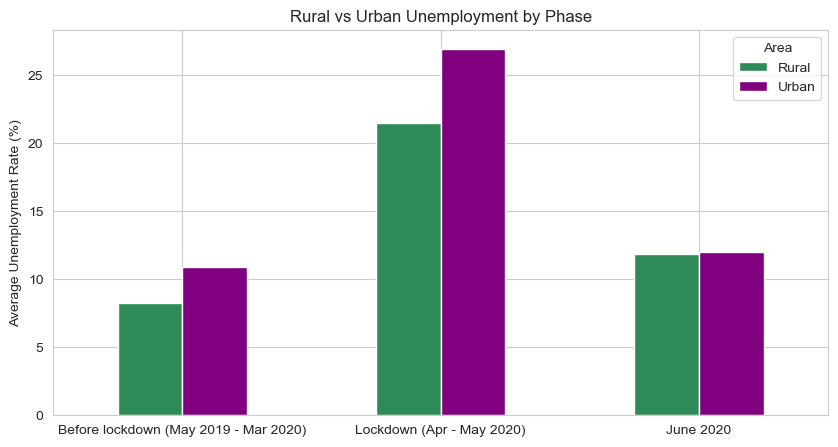

Area,Rural,Urban
Phase,,
Before lockdown (May 2019 - Mar 2020),8.2,10.9
Lockdown (Apr - May 2020),21.5,26.9
June 2020,11.8,12.0


In [46]:
# Label each month with its phase (this dataset ends in June 2020, so recovery is only one month)
def assign_phase_india(date):
    if date <= pd.Timestamp('2020-03-31'):
        return 'Before lockdown (May 2019 - Mar 2020)'
    elif date <= pd.Timestamp('2020-05-31'):
        return 'Lockdown (Apr - May 2020)'
    else:
        return 'June 2020'

df_india['Phase'] = df_india['Date'].apply(assign_phase_india)
phase_order_india = ['Before lockdown (May 2019 - Mar 2020)', 'Lockdown (Apr - May 2020)', 'June 2020']

# Average rate per phase for rural and urban
area_phase = df_india.pivot_table(index='Phase', columns='Area', values='Unemployment_Rate').reindex(phase_order_india)

area_phase.plot(kind='bar', figsize=(10, 5), color=['seagreen', 'purple'])
plt.ylabel("Average Unemployment Rate (%)")
plt.xlabel("")
plt.title("Rural vs Urban Unemployment by Phase")
plt.xticks(rotation=0)
plt.legend(title='Area')
plt.show()

area_phase.round(1)

In [47]:
# Before the lockdown: in how many states was urban unemployment higher than rural?
pre = df_india[df_india['Phase'] == phase_order_india[0]].pivot_table(
    index='Region', columns='Area', values='Unemployment_Rate').dropna()
pre['Gap'] = pre['Urban'] - pre['Rural']

print(f"States with both rural and urban data: {len(pre)}")
print(f"States where urban > rural: {(pre['Gap'] > 0).sum()}")

# The three largest gaps and the states where rural was higher
print(pre.sort_values('Gap', ascending=False).round(1).head(3))
print(pre.sort_values('Gap').round(1).head(3))

States with both rural and urban data: 27
States where urban > rural: 25
Area              Rural  Urban   Gap
Region                              
Jharkhand           8.6   19.3  10.7
Bihar              11.1   16.9   5.8
Himachal Pradesh   17.1   21.7   4.6
Area       Rural  Urban  Gap
Region                      
Odisha       4.9    3.0 -1.9
Kerala       7.5    6.8 -0.7
Telangana    4.8    4.8  0.0


**Observation:** Urban areas were hit harder. Urban unemployment rose from 10.9% to 26.9% during
the lockdown (+16.0 points), while rural rose from 8.2% to 21.5% (+13.3 points). Even before the
lockdown, urban unemployment exceeded rural in 25 of the 27 states with both readings (the
exceptions are Odisha and Kerala). The largest urban-rural gaps were in Jharkhand (19.3% vs
8.6%), Bihar (16.9% vs 11.1%) and Himachal Pradesh (21.7% vs 17.1%).

### 6.3 Jobs Lost: Rural vs Urban

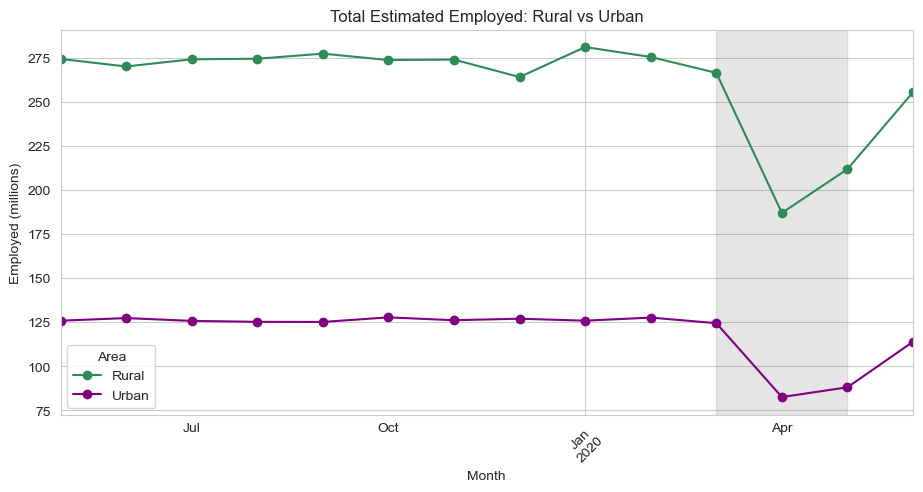

In [48]:
# Total estimated employed per month for rural and urban areas, in millions
employed_area = df_india.groupby(['Date', 'Area'])['Employed'].sum().unstack() / 1e6

employed_area.plot(figsize=(11, 5), marker='o', color=['seagreen', 'purple'])
plt.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-05-31'), color='grey', alpha=0.2)
plt.title("Total Estimated Employed: Rural vs Urban")
plt.xlabel("Month")
plt.ylabel("Employed (millions)")
plt.xticks(rotation=45)
plt.show()

In [49]:
# Percentage change in employment compared with March 2020
change_april = (employed_area.loc['2020-04-30'] / employed_area.loc['2020-03-31'] - 1) * 100
change_june = (employed_area.loc['2020-06-30'] / employed_area.loc['2020-03-31'] - 1) * 100

print("March to April (%):\n", change_april.round(1))
print("\nMarch to June (%):\n", change_june.round(1))

March to April (%):
 Area
Rural   -29.8
Urban   -33.7
dtype: float64

March to June (%):
 Area
Rural   -4.1
Urban   -8.5
dtype: float64


**Observation:** Estimated employment fell by about 30% in rural areas (266.4 to 187.0 million)
and 34% in urban areas (124.4 to 82.5 million) between March and April 2020. By June rural
employment was only 4.1% below its March level, while urban employment was still 8.5% below,
so urban areas recovered more slowly. A plausible explanation is that urban workers depend more
on wage and service jobs that stopped under the lockdown, while rural work, especially farming,
continued, but this data cannot test that.

## 7. Labour Participation

The unemployment rate only counts people who are actively looking for work. The **labour
participation rate** (LPR) shows what share of the working-age population is in the labour
force at all (working or looking). Looking at both gives a fuller picture.

### 7.1 Unemployment and Participation Over Time (2020 dataset)

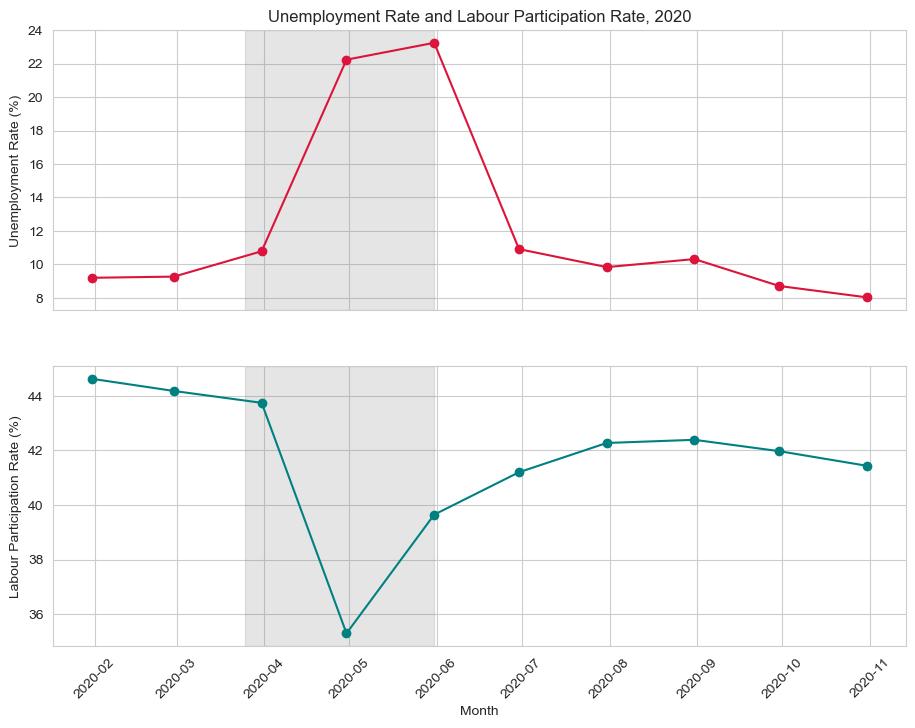

In [50]:
# Average unemployment rate and labour participation rate per month
monthly_ur = df_2020.groupby('Date')['Unemployment_Rate'].mean()
monthly_lpr = df_2020.groupby('Date')['Labour_Participation_Rate'].mean()

# Two stacked charts that share the same time axis
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(monthly_ur.index, monthly_ur.values, marker='o', color='crimson')
axes[0].set_ylabel("Unemployment Rate (%)")
axes[0].set_title("Unemployment Rate and Labour Participation Rate, 2020")

axes[1].plot(monthly_lpr.index, monthly_lpr.values, marker='o', color='teal')
axes[1].set_ylabel("Labour Participation Rate (%)")
axes[1].set_xlabel("Month")

# Shade the approximate national lockdown period on both charts
for ax in axes:
    ax.axvspan(pd.Timestamp('2020-03-25'), pd.Timestamp('2020-05-31'), color='grey', alpha=0.2)

plt.xticks(rotation=45)
plt.show()

In [51]:
# The numbers behind the charts, and how October compares with January
print(pd.concat([monthly_ur.rename('Unemployment'), monthly_lpr.rename('Participation')], axis=1).round(1).T)
print(f"\nOctober vs January: unemployment {monthly_ur.iloc[-1]:.1f}% vs {monthly_ur.iloc[0]:.1f}% | "
      f"participation {monthly_lpr.iloc[-1]:.1f}% vs {monthly_lpr.iloc[0]:.1f}%")

Date           2020-01-31  2020-02-29  2020-03-31  2020-04-30  2020-05-31  \
Unemployment          9.2         9.3        10.8        22.2        23.2   
Participation        44.6        44.2        43.7        35.3        39.6   

Date           2020-06-30  2020-07-31  2020-08-31  2020-09-30  2020-10-31  
Unemployment         10.9         9.8        10.3         8.7         8.0  
Participation        41.2        42.3        42.4        42.0        41.4  

October vs January: unemployment 8.0% vs 9.2% | participation 41.4% vs 44.6%


**Observation:** When unemployment spiked, participation collapsed: the average LPR fell from
43.7% in March to 35.3% in April, its lowest point, while unemployment rose from 10.8% to 22.2%.
The two moved in opposite directions through the year (correlation -0.79 across the 10 monthly
averages, which is a small sample). More importantly, by October the unemployment rate (8.0%)
was below its January level (9.2%), but participation (41.4%) was still 3.2 points below
January (44.6%). So the unemployment rate alone makes the recovery look complete, while part of
the improvement may reflect people who have not returned to the labour force. The data cannot
confirm this, but it is worth checking before declaring the recovery finished.

### 7.2 Participation: Rural vs Urban (India dataset)

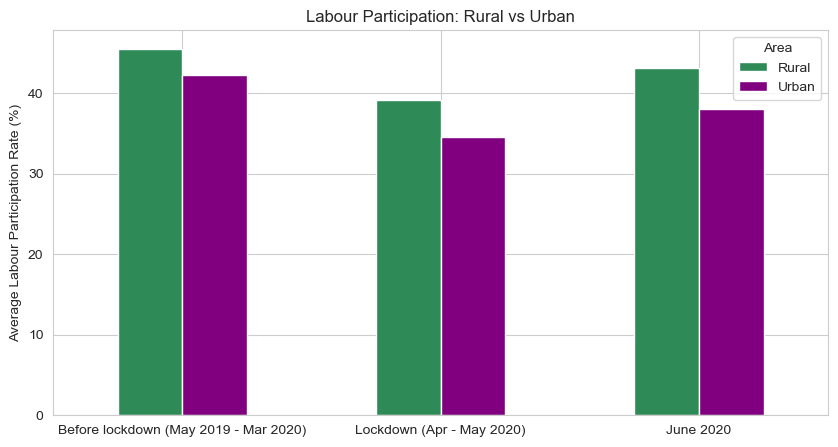

Area,Rural,Urban
Phase,,
Before lockdown (May 2019 - Mar 2020),45.5,42.2
Lockdown (Apr - May 2020),39.2,34.6
June 2020,43.1,38.0


In [52]:
# Average labour participation rate per phase, for rural and urban areas
lpr_area = df_india.pivot_table(index='Phase', columns='Area', values='Labour_Participation_Rate').reindex(phase_order_india)

lpr_area.plot(kind='bar', figsize=(10, 5), color=['seagreen', 'purple'])
plt.ylabel("Average Labour Participation Rate (%)")
plt.xlabel("")
plt.title("Labour Participation: Rural vs Urban")
plt.xticks(rotation=0)
plt.legend(title='Area')
plt.show()

lpr_area.round(1)

In [53]:
# How far below its pre-lockdown level was participation in June 2020?
print((lpr_area.loc['June 2020'] - lpr_area.loc[phase_order_india[0]]).round(1))

Area
Rural   -2.4
Urban   -4.2
dtype: float64


**Observation:** Participation dropped in both areas during the lockdown (rural 45.5% to 39.2%,
urban 42.2% to 34.6%) and had only partly recovered by June 2020. Urban participation was still
4.2 points below its pre-lockdown level, against 2.4 points for rural. This fits the earlier
finding that urban areas recovered more slowly: by June the urban and rural unemployment rates
had converged (about 12%), but urban participation remained much further below normal.

## 8. Patterns Over Time

### 8.1 Is There a Seasonal Pattern?

The India dataset covers only 14 months, with no month appearing in two normal years, so a true
seasonal cycle cannot be established. We can still check whether the pre-Covid months show any
swings, and compare the same months across years.

In [54]:
# Average unemployment rate per month in the India dataset
nat_india = df_india.groupby('Date')['Unemployment_Rate'].mean()

# Pre-Covid months only (May - Dec 2019): how much does the rate move?
pre_covid = nat_india[nat_india.index < '2020-01-01']
print(f"May-Dec 2019: min {pre_covid.min():.2f}% | max {pre_covid.max():.2f}% | std {pre_covid.std():.2f}")

# Same months in 2019 vs 2020
yoy = pd.DataFrame({
    '2019': [nat_india['2019-05-31'], nat_india['2019-06-30']],
    '2020': [nat_india['2020-05-31'], nat_india['2020-06-30']]
}, index=['May', 'June']).round(1)
yoy

May-Dec 2019: min 8.87% | max 9.90% | std 0.39


,2019,2020
May,8.9,24.9
June,9.3,11.9


**Observation:** Before Covid-19 the average unemployment rate barely moved: between May and
December 2019 it stayed within 8.9 to 9.9% (standard deviation 0.4 points), with no clear seasonal
swing. The same months a year later differ enormously (May: 8.9% in 2019 vs 24.9% in 2020; June:
9.3% vs 11.9%), but that gap reflects the lockdown, not seasonality. Identifying genuine seasonal
patterns would need several years of monthly data.

### 8.2 Chronic vs Shock Unemployment

Did states with high unemployment before the lockdown also suffer the biggest rises? We plot
each state's pre-lockdown rate against its lockdown rate. States on the dashed line saw no change.

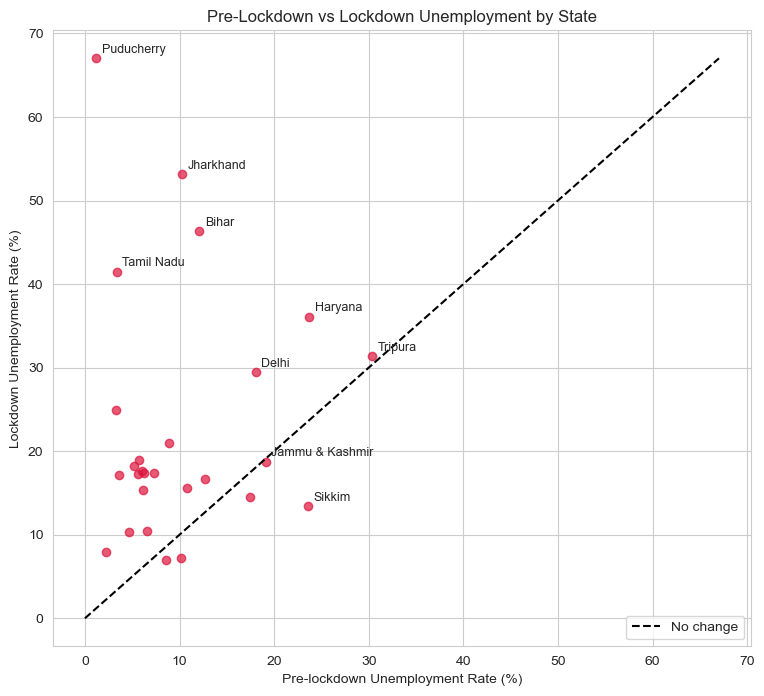

In [55]:
# state_phase was created in section 5.2 (average rate per state in each phase)
plt.figure(figsize=(9, 8))
plt.scatter(state_phase['Pre_lockdown'], state_phase['Lockdown'], color='crimson', alpha=0.7)

# Dashed line: lockdown rate equals pre-lockdown rate (no change)
max_val = state_phase[['Pre_lockdown', 'Lockdown']].max().max()
plt.plot([0, max_val], [0, max_val], 'k--', label='No change')

# Label the states with the highest pre-lockdown or lockdown rates
to_label = set(state_phase.nlargest(5, 'Pre_lockdown').index) | set(state_phase.nlargest(5, 'Lockdown').index)
for state in to_label:
    plt.annotate(state, (state_phase.loc[state, 'Pre_lockdown'], state_phase.loc[state, 'Lockdown']),
                 fontsize=9, xytext=(4, 4), textcoords='offset points')

plt.xlabel("Pre-lockdown Unemployment Rate (%)")
plt.ylabel("Lockdown Unemployment Rate (%)")
plt.title("Pre-Lockdown vs Lockdown Unemployment by State")
plt.legend()
plt.show()

In [56]:
# How strongly are the two related across states?
print("Correlation:", round(state_phase['Pre_lockdown'].corr(state_phase['Lockdown']), 2))

Correlation: 0.04


**Observation:** A state's pre-lockdown unemployment told us almost nothing about how hard the
lockdown would hit it (correlation 0.04). Some states had chronically high unemployment that
barely changed, such as Tripura (30.3% to 31.4%) and Jammu & Kashmir (19.1% to 18.7%). Others had
low unemployment and were hit by a sudden shock: Puducherry (1.2% to 67.0%), Tamil Nadu (3.4% to
41.5%), Jharkhand (10.2% to 53.2%) and Bihar (12.1% to 46.3%). Sikkim moved the other way, from
23.6% to 13.4%. The two groups call for different policies: structural job creation for chronic
cases, and emergency income support for shock-hit states.

## 9. Key Insights and Policy Implications

### 9.1 Key Insights

1. **A sharp but largely temporary shock.** The average state unemployment rate rose from 9.8%
before the lockdown to 22.8% in April and May 2020, then returned to 9.6% over June to October.
Estimated employment fell by about 118 million (30%) in one month, from 392.5 to 274.8 million,
and had recovered to within about 2% of its February level by October.
2. **The shock was very uneven across states.** Puducherry (+66 points), Jharkhand (+43), Tamil
Nadu (+38) and Bihar (+34) were hit hardest, while 5 of 27 states saw no rise. By June to
October, 16 of 27 states were still above their pre-lockdown rate.
3. **Some regions were hit far harder.** The East and South averaged about 34% and 30% during the
lockdown, against about 15% in the West and Northeast. The South recovered below its
pre-lockdown level, while the North had the highest rate in every month except April and May.
4. **Urban areas suffered more and recovered more slowly.** Urban unemployment rose by 16.0 points
against 13.3 for rural, urban employment fell 34% against 30%, and by June 2020 urban employment
was still 8.5% below March (rural: 4.1%).
5. **The unemployment rate alone can mislead.** Participation fell from 43.7% to 35.3% in April.
By October the unemployment rate (8.0%) was below its January level, yet participation (41.4%)
was still 3.2 points lower, so some people may not have returned to the labour force.
6. **Past unemployment did not predict who got hit.** A state's pre-lockdown rate was essentially
unrelated to its lockdown rate (correlation 0.04). Some states had chronic unemployment, others
suffered a sudden shock.
7. **No seasonal pattern can be established.** Before Covid-19 the rate stayed within 8.9 to 9.9%
across May to December 2019, and the data covers too short a period to identify seasonality.

### 9.2 Policy Implications

These follow from the patterns above. They are suggestions for discussion, not proven remedies.

- **Target support by state, not uniformly.** Shock-hit states (e.g. Puducherry, Jharkhand,
Tamil Nadu, Bihar) need fast income and job-bridging support, while chronic-unemployment states
(e.g. Tripura, Haryana, Jammu & Kashmir) need long-term job creation.
- **Strengthen support for urban workers.** Urban areas lost more jobs and recovered more slowly,
so urban employment and wage-support schemes deserve attention. Data on the kinds of jobs lost
would sharpen this.
- **Judge recovery by participation and employment, not only the unemployment rate.** Policy
should track labour participation and employment levels, and offer re-entry support (job
matching, skills training) for people who have left the labour force.
- **Bridge incomes during restrictions.** Employment rebounded quickly once restrictions eased
(about 275 to 374 million in two months), which suggests much of the job loss was temporary.
Protecting incomes during such periods may matter more than long-term retraining.
- **Build better data.** Longer monthly series and population-weighted national figures would
allow proper seasonal analysis and more reliable comparisons.

### 9.3 Caveats

- "Averages" are simple averages across states (or state-area rows), not population-weighted
national figures.
- The data shows when unemployment changed, not why. We attribute the spike to the lockdown
because of its timing, but this analysis cannot separate the pandemic from the restrictions.
- The two datasets overlap in Jan to Jun 2020 with slightly different values, so they were
analyzed separately rather than combined.
- A few rows report exactly 0% unemployment, which may be small-sample artifacts.